# Sales Forecasting & Business Intelligence System

# Project Objective

This project analyzes historical online retail sales data  to identify sales trends, business performance, and customer purchasing patterns.


The project also develops a time -series forcasting model to predict future sales and provides business ind=sights through an interactive dashboard.

# Technologies Used
    Python
    Pandas
    NumPy
    Matplotlib
    Seaborn
    Scikit -learn
    Time Series Forecasting
    Streamlit

In [1]:
# Import pandas for data loading and data manipulation
import pandas as pd

# Import numpy for numerical calculations
import numpy as np

# Import matplotlib for creating visualizations
import matplotlib.pyplot as plt

# Import seaborn for advanced statistical visualizations
import seaborn as sns

# Display all columns when viewing DataFrames
pd.set_option("display.max_columns", None)

# Display the first five rows of the dataset
print("Libraries imported successfully!")

Libraries imported successfully!


# Raw Dataset Load

In [2]:
# Load the raw Online Retail dataset
df = pd.read_csv("../data/OnlineRetail.csv", encoding="ISO-8859-1")

# Display the first 5 rows of the dataset
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
# Display the total number of rows and columns
print("Dataset Shape:", df.shape)

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


#  Data Types & Missing Values

In [4]:
# Display information about the dataset
# This shows column names, data types, and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [5]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Display missing values for each column
print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [6]:
# Check the percentage of missing values in each column
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Create a summary table for missing values
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})

# Display the missing-value summary
missing_summary

,Missing Values,Missing Percentage
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.268311
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000


# 2. Data Quality Check

In this section, we inspect the dataset structure, data types, and
missing values before performing data cleaning.

# Duplicate rows check

In [7]:
# Count the total number of duplicate rows
duplicate_rows = df.duplicated().sum()

# Display the number of duplicate rows
print("Total Duplicate Rows:", duplicate_rows)

Total Duplicate Rows: 5268


# Quantity check

In [8]:
# Count transactions where quantity is zero or negative
invalid_quantity = (df["Quantity"] <= 0).sum()

# Display the number of invalid quantity records
print("Invalid Quantity Records:", invalid_quantity)

Invalid Quantity Records: 10624


# Unit Price check

In [9]:
# Count transactions where unit price is zero or negative
invalid_price = (df["UnitPrice"] <= 0).sum()

# Display the number of invalid price records
print("Invalid Unit Price Records:", invalid_price)

Invalid Unit Price Records: 2517


# Cancelled invoices check

In [10]:
# Convert InvoiceNo to string so that we can check invoice prefixes
invoice_numbers = df["InvoiceNo"].astype(str)

# Identify cancelled invoices
cancelled_invoices = invoice_numbers.str.startswith("C").sum()

# Display the number of cancelled invoices
print("Cancelled Invoice Records:", cancelled_invoices)

Cancelled Invoice Records: 9288


# Numerical columns ka summary

In [11]:
# Display statistical summary of numerical columns
df[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


# 3. Data Cleaning

In this section, we clean the raw retail dataset by removing duplicate
records, handling invalid transactions, converting date columns, and
preparing the data for sales analysis and forecasting.

# Create a copy of raw data

In [12]:
# Create a copy so the original raw dataset remains unchanged
df_clean = df.copy()

# Display the original and copied dataset shapes
print("Raw Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)

Raw Dataset Shape: (541909, 8)
Working Dataset Shape: (541909, 8)


# Remove duplicate rows

In [14]:
# Count duplicate rows before removing them
duplicates_before = df_clean.duplicated().sum()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Display the number of removed duplicates
print("Duplicate Rows Removed:", duplicates_before)

# Display the updated dataset shape
print("Shape After Removing Duplicates:", df_clean.shape)

Duplicate Rows Removed: 5268
Shape After Removing Duplicates: (536641, 8)


# Convert columns to correct data types

In [15]:
# Convert InvoiceDate into datetime format
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

# Convert Quantity into numeric format
df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"],
    errors="coerce"
)

# Convert UnitPrice into numeric format
df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"],
    errors="coerce"
)

# Display the updated data types
df_clean[["InvoiceDate", "Quantity", "UnitPrice"]].dtypes

InvoiceDate    datetime64[ns]
Quantity                int64
UnitPrice             float64
dtype: object

# Remove unusable records

In [16]:
# Count records before filtering
rows_before = len(df_clean)

# Identify cancelled invoices using the invoice number prefix
cancelled_mask = df_clean["InvoiceNo"].astype(str).str.startswith("C")

# Keep valid, non-cancelled sales transactions
df_clean = df_clean[
    (~cancelled_mask)
    & (df_clean["Quantity"] > 0)
    & (df_clean["UnitPrice"] > 0)
    & (df_clean["InvoiceDate"].notna())
].copy()

# Calculate how many records were excluded
rows_removed = rows_before - len(df_clean)

# Display cleaning results
print("Rows Before Filtering:", rows_before)
print("Invalid/Cancelled Rows Removed:", rows_removed)
print("Rows After Filtering:", len(df_clean))

Rows Before Filtering: 536641
Invalid/Cancelled Rows Removed: 11763
Rows After Filtering: 524878


# Create Revenue column

In [17]:
# Calculate revenue for each transaction
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# Display the first five rows of the cleaned data
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


# Save cleaned dataset

In [19]:
# Save cleaned data inside the project's data folder
df_clean.to_csv("../data/OnlineRetail_Cleaned.csv", index=False)

# Confirm that the cleaned dataset has been saved
print("Cleaned dataset saved successfully!")
print("Final Dataset Shape:", df_clean.shape)

Cleaned dataset saved successfully!
Final Dataset Shape: (524878, 9)



# 4. Exploratory Data Analysis (EDA)

In this section, we analyze cleaned retail data to understand sales
performance, revenue trends, and customer purchasing behavior.

# Basic sales summary

In [20]:

# Display the number of valid transaction records
print("Total Transactions:", len(df_clean))

# Display the total revenue generated
print("Total Revenue:", round(df_clean["Revenue"].sum(), 2))

# Display the total quantity of products sold
print("Total Quantity Sold:", df_clean["Quantity"].sum())

# Count unique invoices
print("Unique Invoices:", df_clean["InvoiceNo"].nunique())

# Count unique customers, excluding missing customer IDs
print("Unique Customers:", df_clean["CustomerID"].nunique())

Total Transactions: 524878
Total Revenue: 10642110.8
Total Quantity Sold: 5572420
Unique Invoices: 19960
Unique Customers: 4338


#  Prepare daily and monthly sales

In [21]:

# Create a daily sales dataset by summing transaction revenue per day
daily_sales = (
    df_clean
    .set_index("InvoiceDate")["Revenue"]
    .resample("D")
    .sum()
    .reset_index()
)

# Create a monthly sales dataset by summing transaction revenue per month
monthly_sales = (
    df_clean
    .set_index("InvoiceDate")["Revenue"]
    .resample("MS")
    .sum()
    .reset_index()
)

# Rename columns for clarity
daily_sales.columns = ["Date", "Sales"]
monthly_sales.columns = ["Date", "Sales"]

# Display the first five records of each dataset
print("Daily Sales:")
display(daily_sales.head())

print("Monthly Sales:")
display(monthly_sales.head())

Daily Sales:


,Date,Sales
0,2010-12-01,58776.79
1,2010-12-02,47629.42
2,2010-12-03,46898.63
3,2010-12-04,0.00
4,2010-12-05,31364.63


Monthly Sales:


,Date,Sales
0,2010-12-01,821452.730
1,2011-01-01,689811.610
2,2011-02-01,522545.560
3,2011-03-01,716215.260
4,2011-04-01,536968.491


# Visualize monthly sales trend

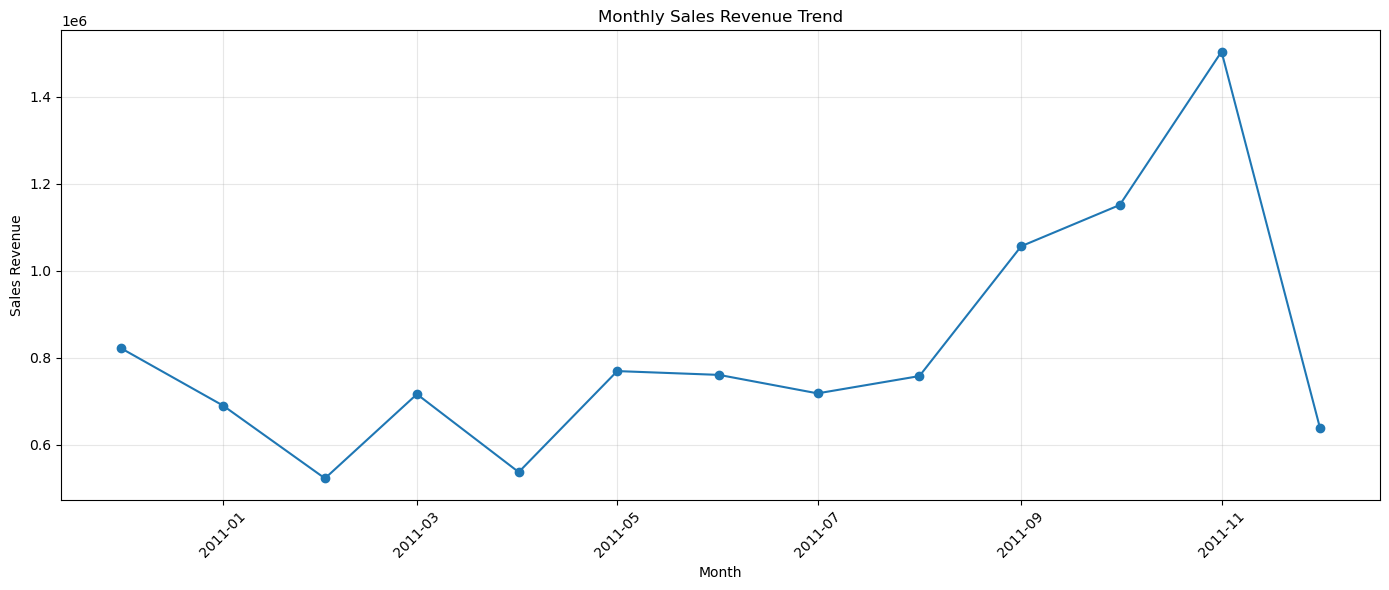

In [22]:

# Set the figure size for readability
plt.figure(figsize=(14, 6))

# Plot monthly sales over time
plt.plot(
    monthly_sales["Date"],
    monthly_sales["Sales"],
    marker="o"
)

# Add a descriptive chart title and axis labels
plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Sales Revenue")

# Rotate date labels for readability
plt.xticks(rotation=45)

# Add grid lines
plt.grid(True, alpha=0.3)

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

# Find the best-performing months

In [23]:

# Sort monthly sales from highest to lowest
top_months = monthly_sales.sort_values(
    by="Sales",
    ascending=False
)

# Display the five months with the highest sales
print("Top 5 Months by Sales Revenue:")
display(top_months.head(5))

Top 5 Months by Sales Revenue:


,Date,Sales
11,2011-11-01,1503866.780
10,2011-10-01,1151263.730
9,2011-09-01,1056435.192
0,2010-12-01,821452.730
5,2011-05-01,769296.610



# 5. Country-Wise and Product-Wise Sales Analysis

This section identifies top-performing countries and products based on
total sales revenue and helps uncover important business opportunities.

# Top 10 countries by revenue

In [25]:

# Group transactions by country and calculate total revenue
country_sales = (
    df_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Display the top 10 countries by revenue
top_countries = country_sales.head(10)

print("Top 10 Countries by Revenue:")
display(top_countries)

Top 10 Countries by Revenue:


,Country,Revenue
0,United Kingdom,9001744.094
1,Netherlands,285446.340
2,EIRE,283140.520
3,Germany,228678.400
4,France,209625.370
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,57067.600
8,Belgium,41196.340
9,Sweden,38367.830


# Visualize country-wise revenue

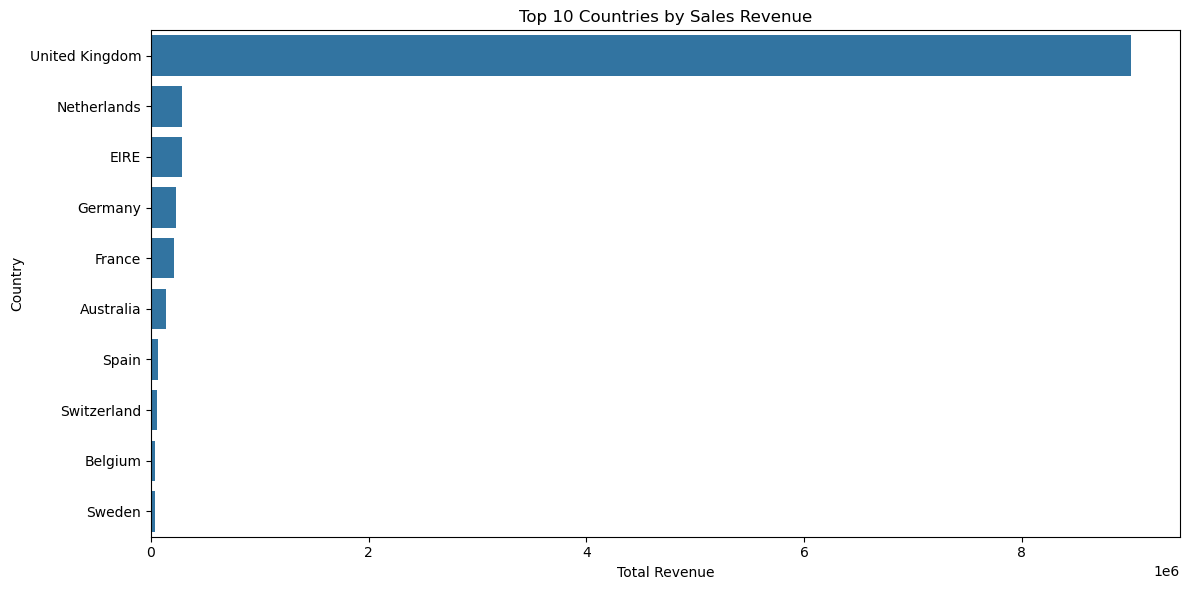

In [26]:

# Create a bar chart for the top 10 countries
plt.figure(figsize=(12, 6))

# Plot country names against total revenue
sns.barplot(
    data=top_countries,
    x="Revenue",
    y="Country"
)

# Add chart title and labels
plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

# Top 10 products by revenue

In [27]:

# Group transactions by product description and calculate revenue
product_sales = (
    df_clean.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Display the top 10 products by revenue
top_products = product_sales.head(10)

print("Top 10 Products by Revenue:")
display(top_products)

Top 10 Products by Revenue:


,Description,Revenue
0,DOTCOM POSTAGE,206248.77
1,REGENCY CAKESTAND 3 TIER,174156.54
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
4,PARTY BUNTING,99445.23
5,JUMBO BAG RED RETROSPOT,94159.81
6,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,POSTAGE,78101.88
8,Manual,77752.82
9,RABBIT NIGHT LIGHT,66870.03


# Visualize product performance

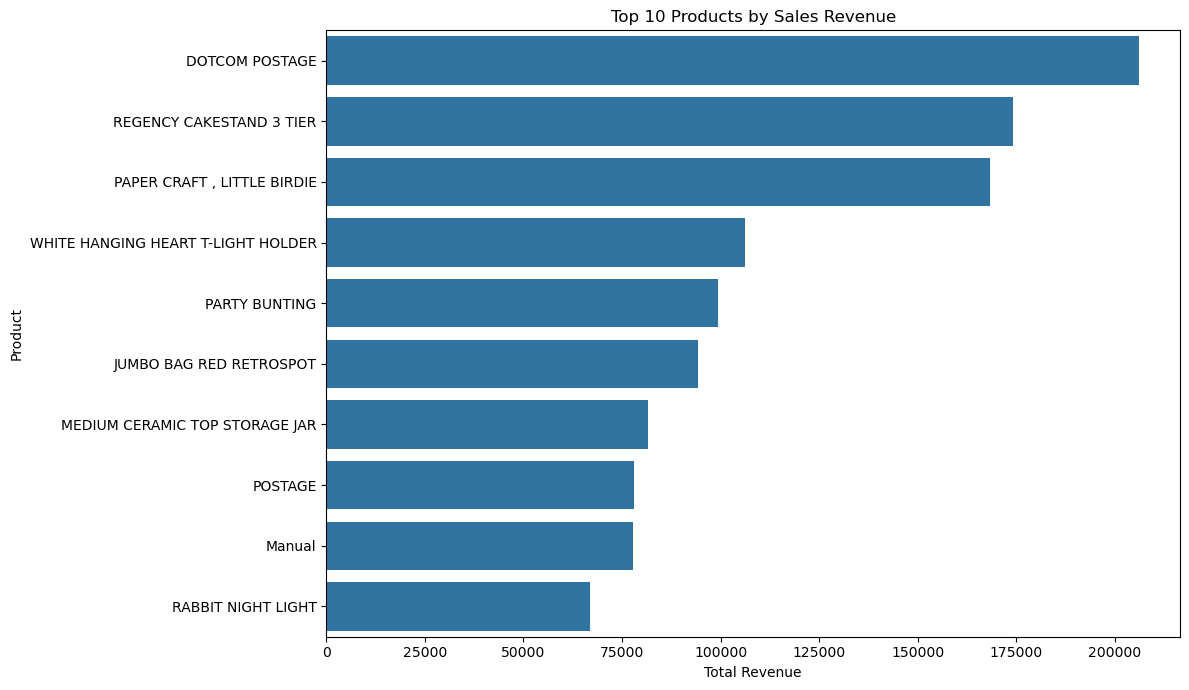

In [28]:

# Create a horizontal bar chart for top products
plt.figure(figsize=(12, 7))

# Plot product descriptions against total revenue
sns.barplot(
    data=top_products,
    x="Revenue",
    y="Description"
)

# Add chart title and axis labels
plt.title("Top 10 Products by Sales Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

# Save monthly sales for forecasting

In [29]:

# Save monthly sales data for later forecasting steps
monthly_sales.to_csv("../data/monthly_sales.csv", index=False)

# Confirm that the file has been saved
print("Monthly sales dataset saved successfully!")
print("File: data/monthly_sales.csv")

Monthly sales dataset saved successfully!
File: data/monthly_sales.csv


# 6. Prepare Daily Sales Data

#  Daily data check

In [30]:
# Convert the Date column into datetime format
daily_sales["Date"] = pd.to_datetime(daily_sales["Date"])

# Sort the records by date
daily_sales = daily_sales.sort_values("Date").reset_index(drop=True)

# Display the first five daily sales records
display(daily_sales.head())

# Display the starting and ending dates
print("Start Date:", daily_sales["Date"].min())
print("End Date:", daily_sales["Date"].max())

# Display the total number of daily records
print("Total Daily Records:", len(daily_sales))

# Count days with zero sales
print("Zero-Sales Days:", (daily_sales["Sales"] == 0).sum())

,Date,Sales
0,2010-12-01,58776.79
1,2010-12-02,47629.42
2,2010-12-03,46898.63
3,2010-12-04,0.00
4,2010-12-05,31364.63


Start Date: 2010-12-01 00:00:00
End Date: 2011-12-09 00:00:00
Total Daily Records: 374
Zero-Sales Days: 69


# Daily sales trend

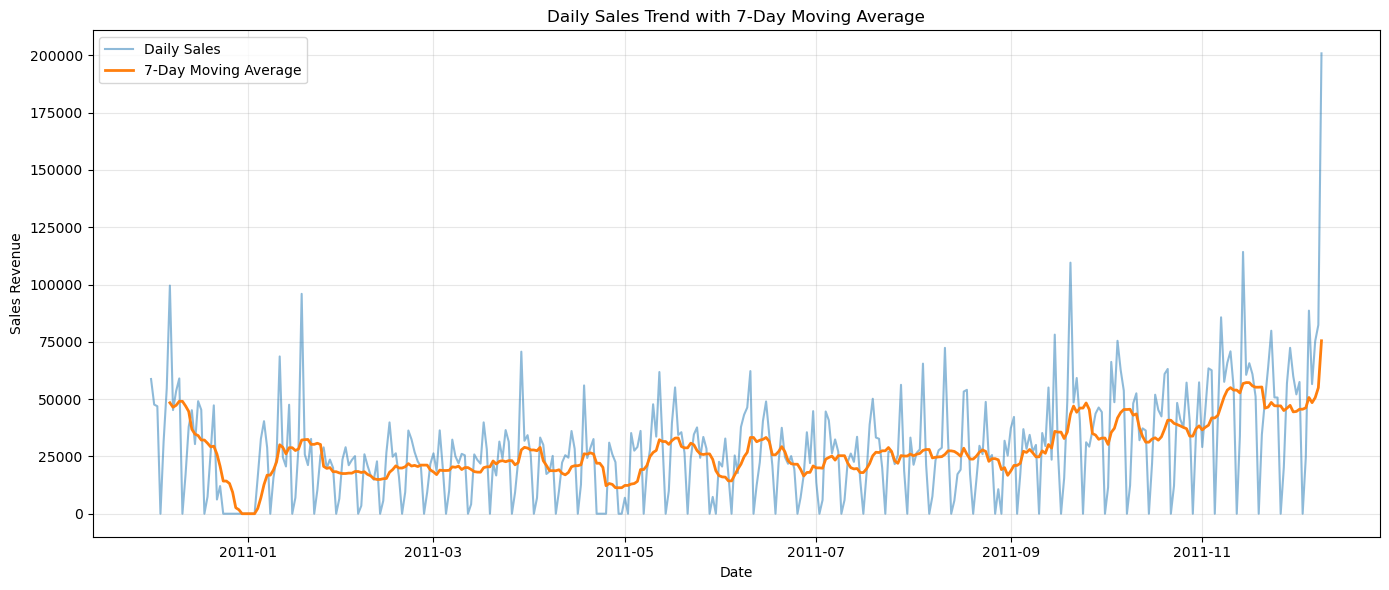

In [31]:
# Calculate the 7-day moving average of sales
daily_sales["7_Day_Moving_Average"] = (
    daily_sales["Sales"].rolling(window=7).mean()
)

# Create a chart with a suitable size
plt.figure(figsize=(14, 6))

# Plot daily sales
plt.plot(
    daily_sales["Date"],
    daily_sales["Sales"],
    label="Daily Sales",
    alpha=0.5
)

# Plot the 7-day moving average
plt.plot(
    daily_sales["Date"],
    daily_sales["7_Day_Moving_Average"],
    label="7-Day Moving Average",
    linewidth=2
)

# Add the chart title and axis labels
plt.title("Daily Sales Trend with 7-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Sales Revenue")

# Display the legend and grid
plt.legend()
plt.grid(True, alpha=0.3)

# Adjust spacing and display the chart
plt.tight_layout()
plt.show()

# Save forecasting data

In [32]:
# Select the columns required for forecasting
forecast_data = daily_sales[["Date", "Sales"]].copy()

# Save the daily sales data in the data folder
forecast_data.to_csv("../data/daily_sales_forecasting.csv", index=False)

# Display confirmation and dataset details
print("Daily forecasting data saved successfully!")
print("Dataset Shape:", forecast_data.shape)
print("File: data/daily_sales_forecasting.csv")

Daily forecasting data saved successfully!
Dataset Shape: (374, 2)
File: data/daily_sales_forecasting.csv


# 7. Feature Engineering

# Create date-based features

In [33]:
# Create a copy of the daily forecasting dataset
forecast_df = forecast_data.copy()

# Ensure the Date column uses datetime format
forecast_df["Date"] = pd.to_datetime(forecast_df["Date"])

# Extract calendar features from the date
forecast_df["Day"] = forecast_df["Date"].dt.day
forecast_df["DayOfWeek"] = forecast_df["Date"].dt.dayofweek
forecast_df["Month"] = forecast_df["Date"].dt.month
forecast_df["Quarter"] = forecast_df["Date"].dt.quarter
forecast_df["Year"] = forecast_df["Date"].dt.year

# Mark weekends: Monday = 0 and Sunday = 6
forecast_df["IsWeekend"] = (
    forecast_df["DayOfWeek"] >= 5
).astype(int)

# Display the new features
display(forecast_df.head())

,Date,Sales,Day,DayOfWeek,Month,Quarter,Year,IsWeekend
0,2010-12-01,58776.79,1,2,12,4,2010,0
1,2010-12-02,47629.42,2,3,12,4,2010,0
2,2010-12-03,46898.63,3,4,12,4,2010,0
3,2010-12-04,0.00,4,5,12,4,2010,1
4,2010-12-05,31364.63,5,6,12,4,2010,1


# Create past-sales features

In [34]:
# Use sales from the previous day as a feature
forecast_df["Sales_Lag_1"] = forecast_df["Sales"].shift(1)

# Use sales from seven days earlier
forecast_df["Sales_Lag_7"] = forecast_df["Sales"].shift(7)

# Calculate the average sales of the previous seven days
# Shift first to avoid including the current day's sales
forecast_df["Rolling_Mean_7"] = (
    forecast_df["Sales"].shift(1).rolling(window=7).mean()
)

# Remove rows without enough historical sales data
forecast_df = forecast_df.dropna().reset_index(drop=True)

# Display the updated forecasting dataset
display(forecast_df.head())

# Display the final dataset size
print("Forecasting Dataset Shape:", forecast_df.shape)

,Date,Sales,Day,DayOfWeek,Month,Quarter,Year,IsWeekend,Sales_Lag_1,Sales_Lag_7,Rolling_Mean_7
0,2010-12-08,45235.36,8,2,12,4,2010,0,99553.85,58776.79,48406.781429
1,2010-12-09,53548.19,9,3,12,4,2010,0,45235.36,47629.42,46472.291429
2,2010-12-10,59021.02,10,4,12,4,2010,0,53548.19,46898.63,47317.830000
3,2010-12-11,0.00,11,5,12,4,2010,1,59021.02,0.00,49049.600000
4,2010-12-12,17125.65,12,6,12,4,2010,1,0.00,31364.63,49049.600000


Forecasting Dataset Shape: (367, 11)


# Save the feature dataset

In [35]:
# Save the prepared dataset for model training
forecast_df.to_csv(
    "../data/forecasting_features.csv",
    index=False
)

# Confirm that the file was saved
print("Forecasting features saved successfully!")
print("File: data/forecasting_features.csv")

Forecasting features saved successfully!
File: data/forecasting_features.csv


# 8. Prepare Training and Testing Data

# Select features and target

In [36]:
# Import the function used to evaluate regression models
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define the input features for the forecasting model
feature_columns = [
    "Day",
    "DayOfWeek",
    "Month",
    "Quarter",
    "Year",
    "IsWeekend",
    "Sales_Lag_1",
    "Sales_Lag_7",
    "Rolling_Mean_7"
]

# Store the input features in X
X = forecast_df[feature_columns]

# Store daily sales as the target variable y
y = forecast_df["Sales"]

# Display the dimensions of the features and target
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (367, 9)
Target Shape: (367,)


# Split data by date

In [37]:
# Calculate the index for an 80% training and 20% testing split
split_index = int(len(forecast_df) * 0.80)

# Select the earlier 80% for training
X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]

# Select the latest 20% for testing
X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

# Display the number of records in each set
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

# Display the date range used for training and testing
print("Training Period:", forecast_df["Date"].iloc[0], "to",
      forecast_df["Date"].iloc[split_index - 1])
print("Testing Period:", forecast_df["Date"].iloc[split_index], "to",
      forecast_df["Date"].iloc[-1])

Training Records: 293
Testing Records: 74
Training Period: 2010-12-08 00:00:00 to 2011-09-26 00:00:00
Testing Period: 2011-09-27 00:00:00 to 2011-12-09 00:00:00


# Train a forecasting model

Sales forecasting model trained successfully!
Predictions generated: 74
Top 10 Important Features:


,Feature,Importance
7,Sales_Lag_7,0.336861
1,DayOfWeek,0.190149
8,Rolling_Mean_7,0.127313
5,IsWeekend,0.106870
6,Sales_Lag_1,0.093034
0,Day,0.073068
2,Month,0.050565
3,Quarter,0.014471
4,Year,0.007668


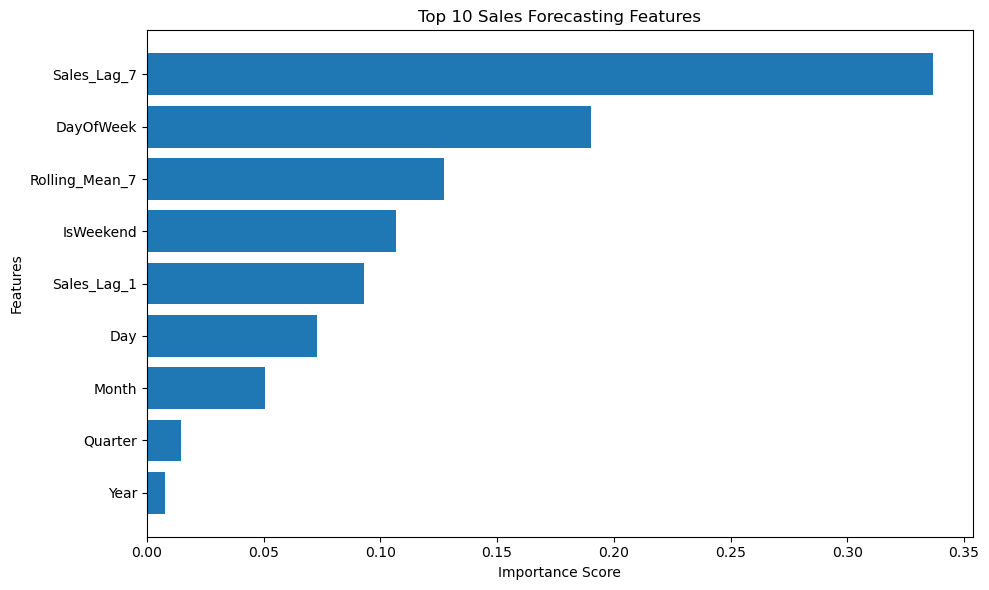

In [47]:
# Import the Random Forest regression algorithm
from sklearn.ensemble import RandomForestRegressor

# Create the forecasting model
sales_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model using historical training data
sales_model.fit(X_train, y_train)

# Generate predictions for the testing period
y_pred = sales_model.predict(X_test)

# Confirm that training is complete
print("Sales forecasting model trained successfully!")
print("Predictions generated:", len(y_pred))

# --------------------------------------------------
# FEATURE IMPORTANCE ANALYSIS
# --------------------------------------------------

# Get the importance score of every feature
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": sales_model.feature_importances_
})

# Sort features from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 important features
print("Top 10 Important Features:")
display(feature_importance.head(10))

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"].head(10)[::-1],
    feature_importance["Importance"].head(10)[::-1]
)

plt.title("Top 10 Sales Forecasting Features")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

# Evaluate model performance

In [39]:
# Calculate the Mean Absolute Error
mae = mean_absolute_error(y_test, y_pred)

# Calculate the Root Mean Squared Error
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Calculate the R-squared score
r2 = r2_score(y_test, y_pred)

# Display the evaluation metrics
print("Forecasting Model Performance")
print("------------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared Score:", round(r2, 4))

Forecasting Model Performance
------------------------------
Mean Absolute Error (MAE): 13919.99
Root Mean Squared Error (RMSE): 23731.37
R-squared Score: 0.4029


# Compare Actual and Predicted Sales

# Create comparison table

In [40]:
# Create a table containing actual and predicted sales
results_df = pd.DataFrame({
    "Date": forecast_df["Date"].iloc[split_index:].values,
    "Actual_Sales": y_test.values,
    "Predicted_Sales": y_pred
})

# Calculate the prediction error for each date
results_df["Prediction_Error"] = (
    results_df["Actual_Sales"] - results_df["Predicted_Sales"]
)

# Display the first ten predictions
display(results_df.head(10))

,Date,Actual_Sales,Predicted_Sales,Prediction_Error
0,2011-09-27,36260.91,50653.094406,-14392.184406
1,2011-09-28,43693.08,40286.364725,3406.715275
2,2011-09-29,46343.35,51085.926510,-4742.576510
3,2011-09-30,44347.06,34517.228373,9829.831627
4,2011-10-01,0.00,678.403569,-678.403569
5,2011-10-02,11531.56,17463.581688,-5932.021688
6,2011-10-03,66243.94,32692.084730,33551.855270
7,2011-10-04,48652.54,36862.601323,11789.938677
8,2011-10-05,75460.77,37905.221848,37555.548152
9,2011-10-06,62761.92,43553.938360,19207.981640


# Plot actual vs predicted sales

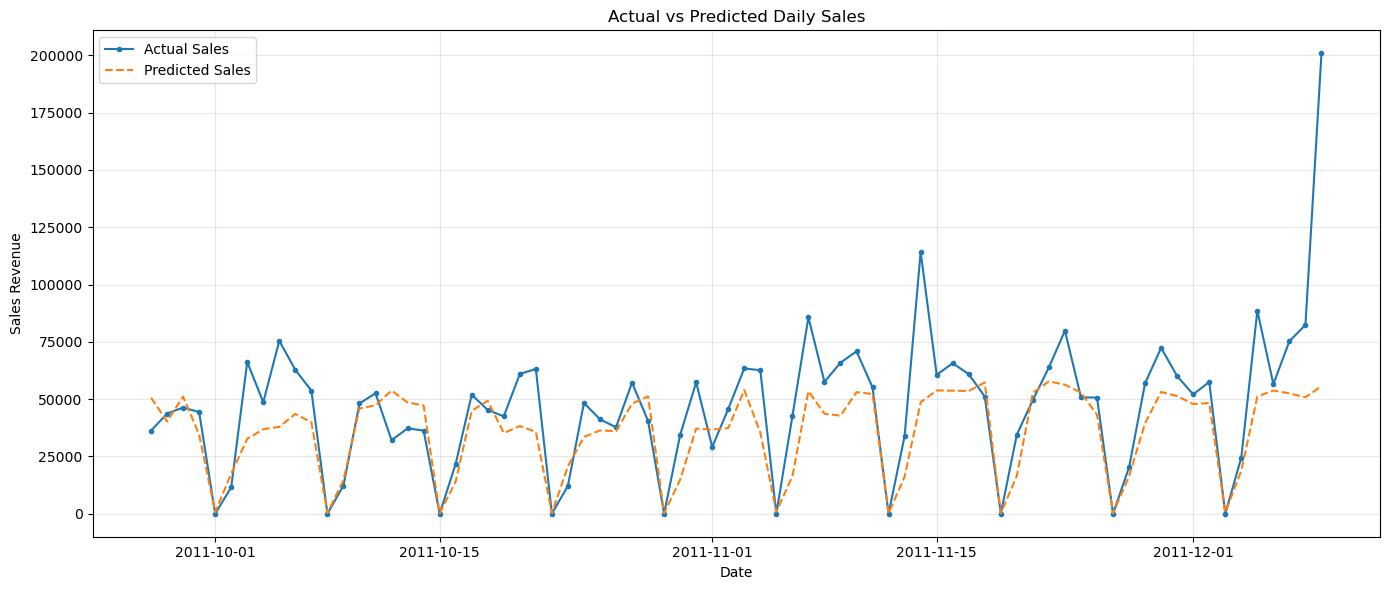

In [41]:
# Create a figure for comparing actual and predicted sales
plt.figure(figsize=(14, 6))

# Plot the actual sales values
plt.plot(
    results_df["Date"],
    results_df["Actual_Sales"],
    label="Actual Sales",
    marker="o",
    markersize=3
)

# Plot the model's predicted sales
plt.plot(
    results_df["Date"],
    results_df["Predicted_Sales"],
    label="Predicted Sales",
    linestyle="--"
)

# Add chart title and axis labels
plt.title("Actual vs Predicted Daily Sales")
plt.xlabel("Date")
plt.ylabel("Sales Revenue")

# Display legend and grid
plt.legend()
plt.grid(True, alpha=0.3)

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

# Compare with a simple baseline

In [42]:
# Use the previous day's actual sales as a simple baseline
baseline_predictions = (
    forecast_df["Sales_Lag_1"].iloc[split_index:].values
)

# Calculate baseline Mean Absolute Error
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

# Display both model and baseline errors
print("Random Forest MAE:", round(mae, 2))
print("Previous-Day Baseline MAE:", round(baseline_mae, 2))

# Check which approach has lower prediction error
if mae < baseline_mae:
    print("Result: Random Forest performed better than the baseline.")
else:
    print("Result: Random Forest did not outperform the baseline.")

Random Forest MAE: 13919.99
Previous-Day Baseline MAE: 24946.26
Result: Random Forest performed better than the baseline.


# Save prediction results

In [43]:
# Save actual and predicted sales for the dashboard
results_df.to_csv(
    "../data/forecast_results.csv",
    index=False
)

# Display confirmation
print("Forecast results saved successfully!")
print("File: data/forecast_results.csv")

Forecast results saved successfully!
File: data/forecast_results.csv


# 9. Save the Forecasting Model

# Create the models folder and save model

In [44]:
# Import joblib to save and load machine learning models
import joblib

# Import Path to work with project folders safely
from pathlib import Path

# Create the models folder if it does not already exist
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save the trained Random Forest model
joblib.dump(
    sales_model,
    models_dir / "sales_forecasting_model.pkl"
)

# Display confirmation
print("Forecasting model saved successfully!")
print("Saved at:", models_dir / "sales_forecasting_model.pkl")

Forecasting model saved successfully!
Saved at: ..\models\sales_forecasting_model.pkl


# Save the feature names

In [45]:
# Save the feature names required by the model
joblib.dump(
    feature_columns,
    models_dir / "feature_columns.pkl"
)

# Confirm that the feature list has been saved
print("Feature names saved successfully!")
print("Features:", feature_columns)

Feature names saved successfully!
Features: ['Day', 'DayOfWeek', 'Month', 'Quarter', 'Year', 'IsWeekend', 'Sales_Lag_1', 'Sales_Lag_7', 'Rolling_Mean_7']


# Verify the saved model

In [46]:
# Load the saved model from disk
loaded_model = joblib.load(
    models_dir / "sales_forecasting_model.pkl"
)

# Generate a test prediction using one testing record
sample_prediction = loaded_model.predict(X_test.iloc[[0]])

# Display the test prediction
print("Model loaded successfully!")
print("Sample predicted daily sales:", round(float(sample_prediction[0]), 2))

Model loaded successfully!
Sample predicted daily sales: 50653.09
